# Nifty 50 Risk & Return Analysis (2019–2025)

*Author:* Shweta Gupta

*Objective:* Compare the return, risk and risk-adjusted performance of the Nifty 50 index and 10 large Indian stocks from different sectors, including how they behaved during the COVID-19 crash.

*Tools:* Python (pandas, NumPy, matplotlib, seaborn), yfinance, Google Colab

*Data:* Daily adjusted closing prices from Yahoo Finance, 2 Jan 2019 – 31 Dec 2025 (1,729 trading days)

## 1. Data Collection
Downloaded daily adjusted closing prices for the Nifty 50 and 10 large stocks from different sectors.

In [1]:

!pip install yfinance --quiet

import yfinance as yf
import pandas as pd

tickers = ["^NSEI", "RELIANCE.NS", "HDFCBANK.NS", "INFY.NS", "TCS.NS", "ITC.NS",
           "SUNPHARMA.NS", "MARUTI.NS", "LT.NS", "BHARTIARTL.NS", "HINDUNILVR.NS"]

data = yf.download(tickers, start="2019-01-01", end="2026-01-01", auto_adjust=True)
prices = data["Close"]

print("Shape (rows, columns):", prices.shape)
print(prices.head())
print(prices.tail())

[*********************100%***********************]  11 of 11 completed

Shape (rows, columns): (1730, 11)
Ticker      BHARTIARTL.NS  HDFCBANK.NS  HINDUNILVR.NS     INFY.NS      ITC.NS  \
Date                                                                            
2019-01-01     276.940033   496.185852    1591.314331  529.594177  196.502686   
2019-01-02     271.002533   491.658569    1576.736450  532.779480  195.043015   
2019-01-03     271.739349   487.800995    1580.093628  532.859192  193.826569   
2019-01-04     279.497162   489.106079    1574.174072  526.408813  195.286301   
2019-01-07     281.664062   489.845215    1577.045654  534.889709  195.772842   

Ticker            LT.NS    MARUTI.NS  RELIANCE.NS  SUNPHARMA.NS       TCS.NS  \
Date                                                                           
2019-01-01  1283.006470  6934.815430   496.196381    401.703094  1544.278687   
2019-01-02  1268.413574  6741.011719   489.733887    407.725616  1560.916016   
2019-01-03  1241.274414  6681.743164   483.691895    404.065796  1541.965820  

## 2. Data Cleaning
Forward-filled gaps in the middle of the data and dropped the first row, which had no earlier price.

In [2]:
print("Missing values per column:")
print(prices.isna().sum())

prices_clean = prices.ffill().dropna()

print("\nMissing values after cleaning:", prices_clean.isna().sum().sum())
print("Shape after cleaning:", prices_clean.shape)
print(prices_clean.head(3))

Missing values per column:
Ticker
BHARTIARTL.NS    0
HDFCBANK.NS      0
HINDUNILVR.NS    0
INFY.NS          0
ITC.NS           0
LT.NS            0
MARUTI.NS        0
RELIANCE.NS      0
SUNPHARMA.NS     0
TCS.NS           0
^NSEI            3
dtype: int64

Missing values after cleaning: 0
Shape after cleaning: (1729, 11)
Ticker      BHARTIARTL.NS  HDFCBANK.NS  HINDUNILVR.NS     INFY.NS      ITC.NS  \
Date                                                                            
2019-01-02     271.002533   491.658569    1576.736450  532.779480  195.043015   
2019-01-03     271.739349   487.800995    1580.093628  532.859192  193.826569   
2019-01-04     279.497162   489.106079    1574.174072  526.408813  195.286301   

Ticker            LT.NS    MARUTI.NS  RELIANCE.NS  SUNPHARMA.NS       TCS.NS  \
Date                                                                           
2019-01-02  1268.413574  6741.011719   489.733887    407.725616  1560.916016   
2019-01-03  1241.274414  6681.7

## 3. Returns (CAGR)

In [3]:
daily_returns = prices_clean.pct_change().dropna()

years = (prices_clean.index[-1] - prices_clean.index[0]).days / 365.25
cagr = (prices_clean.iloc[-1] / prices_clean.iloc[0]) ** (1 / years) - 1

print("Years covered:", round(years, 2))
print("\nFirst 3 days of daily returns (%):")
print((daily_returns.head(3) * 100).round(2))
print("\nAnnual return (CAGR %), highest to lowest:")
print((cagr * 100).round(2).sort_values(ascending=False))

Years covered: 7.0

First 3 days of daily returns (%):
Ticker      BHARTIARTL.NS  HDFCBANK.NS  HINDUNILVR.NS  INFY.NS  ITC.NS  LT.NS  \
Date                                                                            
2019-01-03           0.27        -0.78           0.21     0.01   -0.62  -2.14   
2019-01-04           2.85         0.27          -0.37    -1.21    0.75  -0.50   
2019-01-07           0.78         0.15           0.18     1.61    0.25  -0.31   

Ticker      MARUTI.NS  RELIANCE.NS  SUNPHARMA.NS  TCS.NS  ^NSEI  
Date                                                             
2019-01-03      -0.88        -1.23         -0.90   -1.21  -1.11  
2019-01-04       0.42         0.54         -0.53   -1.22   0.52  
2019-01-07       1.76         0.56         -0.69    1.12   0.41  

Annual return (CAGR %), highest to lowest:
Ticker
BHARTIARTL.NS    33.82
SUNPHARMA.NS     22.69
RELIANCE.NS      18.05
LT.NS            18.03
INFY.NS          16.45
MARUTI.NS        13.68
^NSEI            13.

*Findings:* Over 2019–2025, the Nifty 50 returned 13.47% a year. Out of the 10 stocks beat it, led by Bharti at (33.82%). Hindunilvr had the lowest return (5.50%), despite being seen as a "safe" blue-chip.

## 4. Risk (Annualised Volatility)

In [4]:
volatility = daily_returns.std() * (252 ** 0.5)

summary = pd.DataFrame({
    "CAGR %": (cagr * 100).round(2),
    "Volatility %": (volatility * 100).round(2)
}).sort_values("Volatility %")

print(summary)

               CAGR %  Volatility %
Ticker                             
^NSEI           13.47         17.56
HINDUNILVR.NS    5.50         22.57
TCS.NS          10.17         23.64
ITC.NS          10.18         23.93
HDFCBANK.NS     10.28         24.92
SUNPHARMA.NS    22.69         25.97
LT.NS           18.03         27.32
INFY.NS         16.45         27.47
RELIANCE.NS     18.05         28.10
BHARTIARTL.NS   33.82         28.53
MARUTI.NS       13.68         28.95


*Findings:* The Nifty 50 had the lowest volatility (17.56%), lower than every individual stock, because diversification across 50 stocks cancels out much of their individual movement. Maruti.ns was the most volatile stock (28.95%).:

## 5. Risk-Adjusted Return (Sharpe Ratio)
Risk-free rate: 6.77%, the 2019–2025 average yield on India's 10-year G-Sec (source: FRED).

In [5]:
risk_free = 0.0677

summary["Sharpe"] = ((cagr - risk_free) / volatility).round(2)

print(summary.sort_values("Sharpe", ascending=False))



               CAGR %  Volatility %  Sharpe
Ticker                                     
BHARTIARTL.NS   33.82         28.53    0.95
SUNPHARMA.NS    22.69         25.97    0.61
LT.NS           18.03         27.32    0.41
RELIANCE.NS     18.05         28.10    0.40
^NSEI           13.47         17.56    0.38
INFY.NS         16.45         27.47    0.35
MARUTI.NS       13.68         28.95    0.24
ITC.NS          10.18         23.93    0.14
TCS.NS          10.17         23.64    0.14
HDFCBANK.NS     10.28         24.92    0.14
HINDUNILVR.NS    5.50         22.57   -0.06


*Findings:* Only Bharti Airtel (0.95) and Sun Pharma (0.61) delivered strong risk-adjusted returns. The Nifty (0.38) beat 6 of the 10 stocks on Sharpe. HUL's Sharpe was negative (−0.06) because its return (5.50%) was below the 6.77% risk-free rate.

## 6. Maximum Drawdown

In [6]:
running_max = prices_clean.cummax()
drawdown = prices_clean / running_max - 1

summary["Max Drawdown %"] = (drawdown.min() * 100).round(2)
summary["Worst Date"] = drawdown.idxmin().dt.date

print(summary.sort_values("Max Drawdown %"))

               CAGR %  Volatility %  Sharpe  Max Drawdown %  Worst Date
Ticker                                                                 
LT.NS           18.03         27.32    0.41          -54.44  2020-03-24
ITC.NS          10.18         23.93    0.14          -51.11  2020-03-16
MARUTI.NS       13.68         28.95    0.24          -48.05  2020-04-03
RELIANCE.NS     18.05         28.10    0.40          -45.09  2020-03-23
HDFCBANK.NS     10.28         24.92    0.14          -41.05  2020-03-24
^NSEI           13.47         17.56    0.38          -38.44  2020-03-23
INFY.NS         16.45         27.47    0.35          -36.55  2020-03-23
TCS.NS          10.17         23.64    0.14          -34.45  2025-09-30
BHARTIARTL.NS   33.82         28.53    0.95          -33.35  2020-10-19
SUNPHARMA.NS    22.69         25.97    0.61          -31.30  2020-03-23
HINDUNILVR.NS    5.50         22.57   -0.06          -30.46  2022-03-07


*Findings:* 8 of 11 tickers hit their worst fall in March–April 2020, during the COVID crash. L&T had the deepest drawdown (-54.44%) The Nifty's drawdown (-38.44%) ranked only 6th of 11, which shows diversification protects less in a crash, when most stocks fall together.

## 7. Market Sensitivity (Beta)

In [7]:
import numpy as np

market = daily_returns["^NSEI"]
betas = {}

for ticker in daily_returns.columns.drop("^NSEI"):
    slope, intercept = np.polyfit(market, daily_returns[ticker], 1)
    betas[ticker] = round(slope, 2)

summary["Beta"] = pd.Series(betas)
summary.loc["^NSEI", "Beta"] = 1.00

print(summary[["CAGR %", "Volatility %", "Max Drawdown %", "Beta"]].sort_values("Beta", ascending=False))

               CAGR %  Volatility %  Max Drawdown %  Beta
Ticker                                                   
RELIANCE.NS     18.05         28.10          -45.09  1.10
HDFCBANK.NS     10.28         24.92          -41.05  1.07
LT.NS           18.03         27.32          -54.44  1.07
^NSEI           13.47         17.56          -38.44  1.00
MARUTI.NS       13.68         28.95          -48.05  1.00
INFY.NS         16.45         27.47          -36.55  0.86
BHARTIARTL.NS   33.82         28.53          -33.35  0.81
TCS.NS          10.17         23.64          -34.45  0.72
ITC.NS          10.18         23.93          -51.11  0.68
SUNPHARMA.NS    22.69         25.97          -31.30  0.62
HINDUNILVR.NS    5.50         22.57          -30.46  0.56


*Findings:* Reliance had the highest beta (1.10) and HUL the lowest (0.56). ITC had a low beta (0.68) but still fell 51.11% from its peak, which shows that a low beta does not mean low risk: its fall was driven by company-specific factors, not the market

## 8. Correlation Across Sectors

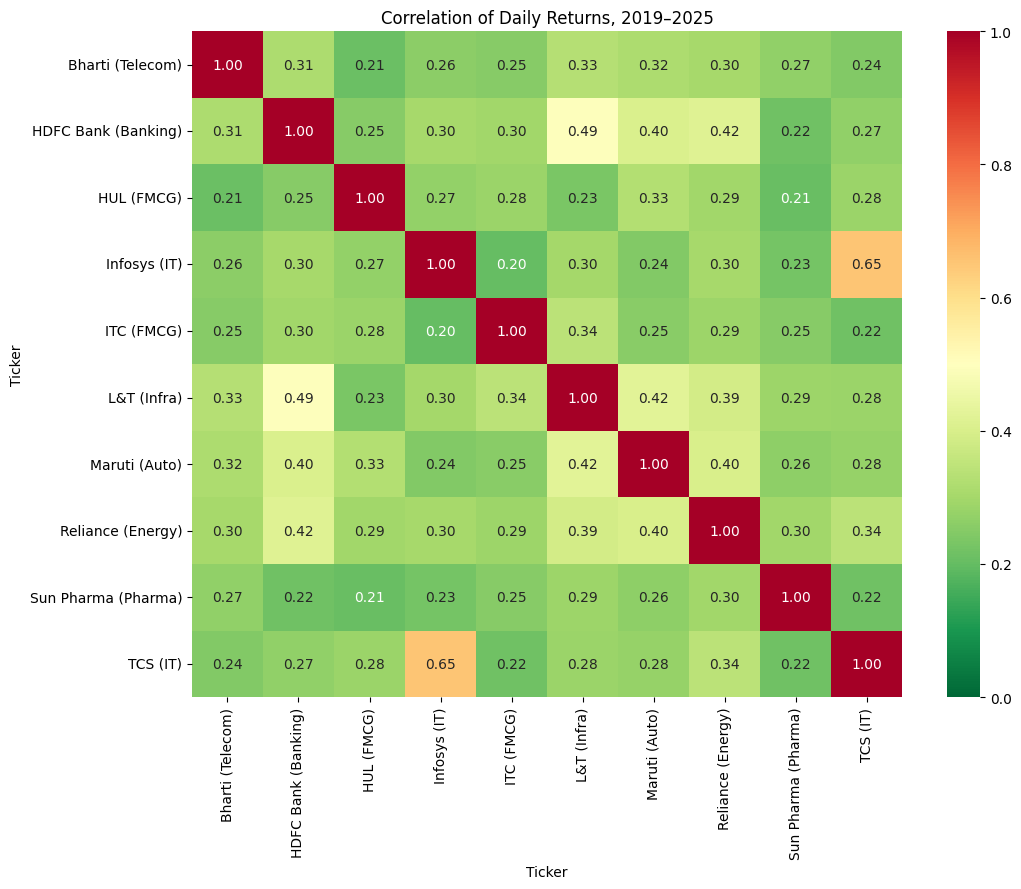

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sectors = {
    "RELIANCE.NS": "Reliance (Energy)", "HDFCBANK.NS": "HDFC Bank (Banking)",
    "INFY.NS": "Infosys (IT)", "TCS.NS": "TCS (IT)",
    "ITC.NS": "ITC (FMCG)", "HINDUNILVR.NS": "HUL (FMCG)",
    "SUNPHARMA.NS": "Sun Pharma (Pharma)", "MARUTI.NS": "Maruti (Auto)",
    "LT.NS": "L&T (Infra)", "BHARTIARTL.NS": "Bharti (Telecom)"
}

corr = daily_returns.drop(columns="^NSEI").corr()
corr = corr.rename(index=sectors, columns=sectors)

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0, vmax=1)
plt.title("Correlation of Daily Returns, 2019–2025")
plt.tight_layout()
plt.show()

*Findings:* The most correlated pair was Infosys and TCS (0.65), both in the IT sector. Most cross-sector pairs were between 0.20 and 0.35, which shows diversification benefits come from spreading across sectors, not just across stocks.

"Stocks in the same sector were the most correlated (Infosys–TCS: 0.65). Cross-sector pairs were mostly between 0.20 and 0.35, which shows diversification benefits come from spreading across sectors, not just across stocks."

## 9. Equal-Weight Portfolio vs Nifty 50

                 Equal-weight portfolio   Nifty 50
CAGR %                            17.54      13.47
Volatility %                      16.11      17.56
Sharpe                             0.67       0.38
Max Drawdown %                   -31.12     -38.44
Final value (₹)               309628.97  242108.87


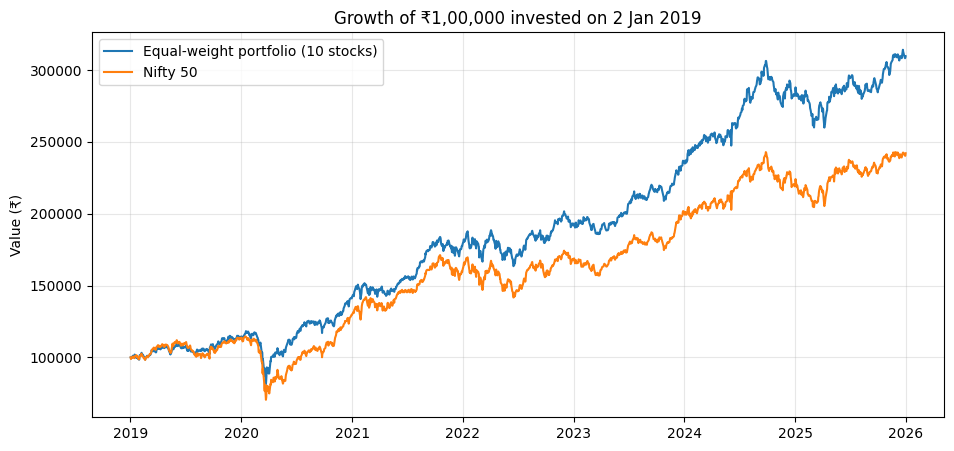

In [9]:
stocks = prices_clean.drop(columns="^NSEI")
growth = stocks / stocks.iloc[0]
portfolio = growth.mean(axis=1) * 100000
nifty = prices_clean["^NSEI"] / prices_clean["^NSEI"].iloc[0] * 100000

port_ret = portfolio.pct_change().dropna()
port_cagr = (portfolio.iloc[-1] / portfolio.iloc[0]) ** (1 / years) - 1
port_vol = port_ret.std() * (252 ** 0.5)
port_sharpe = (port_cagr - risk_free) / port_vol
port_dd = (portfolio / portfolio.cummax() - 1).min()

comparison = pd.DataFrame({
    "Equal-weight portfolio": [port_cagr * 100, port_vol * 100, port_sharpe, port_dd * 100, portfolio.iloc[-1]],
    "Nifty 50": [cagr["^NSEI"] * 100, volatility["^NSEI"] * 100, summary.loc["^NSEI", "Sharpe"],
                 drawdown["^NSEI"].min() * 100, nifty.iloc[-1]]
}, index=["CAGR %", "Volatility %", "Sharpe", "Max Drawdown %", "Final value (₹)"]).round(2)
print(comparison)

plt.figure(figsize=(11, 5))
plt.plot(portfolio, label="Equal-weight portfolio (10 stocks)")
plt.plot(nifty, label="Nifty 50")
plt.title("Growth of ₹1,00,000 invested on 2 Jan 2019")
plt.ylabel("Value (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

*Findings:* ₹1 lakh in the equal-weight portfolio grew to ₹3,09,629, compared with ₹2,42,109 in the Nifty. It beat the Nifty on return (17.54% vs 13.47%), volatility (16.11% vs 17.56%) and Sharpe (0.67 vs 0.38). However, these results are inflated by survivorship bias, since the stocks were chosen in hindsight.

"The equal-weight portfolio outperformed the Nifty on return, risk and Sharpe, but these results are inflated by survivorship bias, since the stocks were chosen in hindsight."

### 10. COVID-19 Crash and Recovery

In [10]:
pre_crash = prices_clean.loc["2020-01-01":"2020-02-19"]
crash = prices_clean.loc["2020-02-20":"2020-04-30"]

peak = pre_crash.max()
trough = crash.min()
trough_date = crash.idxmin()
fall = (trough / peak - 1) * 100

recovered_on = {}
for t in prices_clean.columns:
    after = prices_clean.loc[trough_date[t]:, t]
    back = after[after >= peak[t]]
    recovered_on[t] = back.index[0] if len(back) > 0 else pd.NaT

covid = pd.DataFrame({
    "Fall %": fall.round(2),
    "Trough": trough_date,
    "Recovered on": pd.Series(recovered_on)
})
covid["Days to recover"] = (covid["Recovered on"] - covid["Trough"]).dt.days
covid["Trough"] = covid["Trough"].dt.date
covid["Recovered on"] = covid["Recovered on"].dt.date
covid = covid.rename(index=sectors)

print(covid.sort_values("Fall %"))

                     Fall %      Trough Recovered on  Days to recover
L&T (Infra)          -47.61  2020-03-24   2021-01-04              286
Maruti (Auto)        -46.66  2020-04-03   2020-12-03              244
Reliance (Energy)    -44.08  2020-03-23   2020-06-04               73
HDFC Bank (Banking)  -40.47  2020-03-24   2020-11-06              227
ITC (FMCG)           -39.47  2020-03-16   2021-02-05              326
^NSEI                -38.44  2020-03-23   2020-11-09              231
Infosys (IT)         -34.23  2020-03-23   2020-07-07              106
Bharti (Telecom)     -28.49  2020-03-24   2020-05-19               56
Sun Pharma (Pharma)  -28.10  2020-03-23   2020-04-09               17
TCS (IT)             -26.75  2020-03-19   2020-07-06              109
HUL (FMCG)           -19.80  2020-03-19   2020-03-31               12


*Findings:* L&T fell the most (−47.61%) and HUL fell the least (−19.80%), recovering in just 12 days. Defensive stocks mostly protected investors, with one exception: ITC, which fell 39.47% and took 326 days to recover, worse than the Nifty on both.